<center><h1>Niu_Qiyu_HW4</h1></center>

**Name:** Qiyu Niu  
**GitHub Username:** QiyuNiu  
**USC ID:** 6184595941


## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

The handout says this part is the Homework 3 programming assignment. I kept a
compact rerun here because all of the classification models below use these
cleaned time series and features.


### (a) Obtain Data

I saved the AReM data under `../data/AReM`. There are 88 CSV files in seven
activity folders. Each file should give 480 observations for six time series.


### Imports


In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display
from scipy.special import expit
from scipy.stats import norm
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, confusion_matrix, roc_auc_score, roc_curve
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize

warnings.filterwarnings("ignore", category=ConvergenceWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid", context="notebook")

RANDOM_SEED = 552
DATA_DIR = Path("../data/AReM").resolve()
assert DATA_DIR.exists(), f"Data directory not found: {DATA_DIR}"
print("AReM data directory found.")


AReM data directory found.


Most files are comma-separated, but a few have small formatting problems. The
loader accepts commas or spaces, puts every file on the expected time grid, and
linearly interpolates a missing row if needed. The original CSV files are not
changed.


In [2]:
RAW_COLUMNS = [
    "time", "avg_rss12", "var_rss12", "avg_rss13",
    "var_rss13", "avg_rss23", "var_rss23"
]
SERIES_COLUMNS = RAW_COLUMNS[1:]
EXPECTED_TIMES = np.arange(0, 120_000, 250)
ACTIVITY_ORDER = [
    "bending1", "bending2", "cycling", "lying",
    "sitting", "standing", "walking"
]


def load_instance(path):
    rows = []
    with open(path, "r", encoding="utf-8") as stream:
        for line_number, line in enumerate(stream, start=1):
            if not line.strip() or line.lstrip().startswith("#"):
                continue
            fields = line.replace(",", " ").split()
            if len(fields) != 7:
                raise ValueError(
                    f"{path}, line {line_number}: expected 7 values, "
                    f"found {len(fields)}"
                )
            rows.append([float(value) for value in fields])

    frame = pd.DataFrame(rows, columns=RAW_COLUMNS)
    frame = frame.set_index("time").reindex(EXPECTED_TIMES)
    missing_rows = int(frame.isna().any(axis=1).sum())
    if missing_rows:
        frame = frame.interpolate(method="linear", limit_direction="both")
    if frame.isna().any().any() or frame.shape != (480, 6):
        raise ValueError(f"Cleaning failed for {path}; shape={frame.shape}")
    return frame.to_numpy(dtype=float), missing_rows


metadata_rows = []
all_series = []
for activity in ACTIVITY_ORDER:
    paths = sorted(
        (DATA_DIR / activity).glob("dataset*.csv"),
        key=lambda p: int(re.search(r"(\d+)$", p.stem).group(1)),
    )
    for path in paths:
        dataset_id = int(re.search(r"(\d+)$", path.stem).group(1))
        values, missing_rows = load_instance(path)
        metadata_rows.append(
            {
                "activity": activity,
                "dataset_id": dataset_id,
                "file": f"{activity}/{path.name}",
                "interpolated_rows": missing_rows,
            }
        )
        all_series.append(values)

metadata = pd.DataFrame(metadata_rows)
all_series = np.stack(all_series)
assert metadata.shape[0] == 88
assert all_series.shape == (88, 480, 6)

display(metadata.groupby("activity", sort=False).size().rename("instances").to_frame())
display(metadata.query("interpolated_rows > 0"))
print("Array shape:", all_series.shape)


,instances
activity,
bending1,7
bending2,6
cycling,15
lying,15
sitting,15
standing,15
walking,15


,activity,dataset_id,file,interpolated_rows
50,sitting,8,sitting/dataset8.csv,1


Array shape: (88, 480, 6)


### (b) Splitting Data


In [3]:
def choose_split(activity, dataset_id):
    test_limit = 2 if activity in {"bending1", "bending2"} else 3
    return "test" if dataset_id <= test_limit else "train"


metadata["split"] = [
    choose_split(activity, dataset_id)
    for activity, dataset_id in zip(metadata["activity"], metadata["dataset_id"])
]
train_idx = metadata.index[metadata["split"].eq("train")].to_numpy()
test_idx = metadata.index[metadata["split"].eq("test")].to_numpy()

split_table = pd.crosstab(
    metadata["activity"], metadata["split"], margins=True
).reindex(ACTIVITY_ORDER + ["All"])
display(split_table)
assert len(train_idx) == 69 and len(test_idx) == 19


split,test,train,All
activity,,,
bending1,2,5,7
bending2,2,4,6
cycling,3,12,15
lying,3,12,15
sitting,3,12,15
standing,3,12,15
walking,3,12,15
All,19,69,88


### (c) Feature Extraction

Common time-domain features include minimum, maximum, mean, median, standard
deviation, variance, quartiles, range, interquartile range, root mean square,
skewness, and kurtosis. The required seven features are used below.

I use **minimum, mean, and maximum** for the first plots. Minimum and maximum
describe the range of motion, while the mean describes the usual level during
the activity.


In [4]:
STAT_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]
FEATURE_CACHE = {}


def summarize_chunk(chunk):
    return {
        "min": chunk.min(axis=0),
        "max": chunk.max(axis=0),
        "mean": chunk.mean(axis=0),
        "median": np.median(chunk, axis=0),
        "std": chunk.std(axis=0, ddof=1),
        "q1": np.quantile(chunk, 0.25, axis=0),
        "q3": np.quantile(chunk, 0.75, axis=0),
    }


def segmented_features(l):
    if l in FEATURE_CACHE:
        return FEATURE_CACHE[l]

    feature_names = []
    for segment in range(1, l + 1):
        for series in range(1, 7):
            for stat in STAT_NAMES:
                feature_names.append(f"{stat}_s{series}_seg{segment}")

    rows = []
    for values in all_series:
        row = []
        for chunk in np.array_split(values, l, axis=0):
            stats = summarize_chunk(chunk)
            for series_index in range(6):
                for stat in STAT_NAMES:
                    row.append(stats[stat][series_index])
        rows.append(row)

    frame = pd.DataFrame(rows, columns=feature_names, index=metadata.index)
    FEATURE_CACHE[l] = frame
    return frame


features_l1 = segmented_features(1)
assert features_l1.shape == (88, 42)
display(pd.concat([metadata[["activity", "dataset_id", "split"]], features_l1], axis=1).head())
print("Feature matrix shape:", features_l1.shape)


,activity,dataset_id,split,min_s1_seg1,max_s1_seg1,mean_s1_seg1,median_s1_seg1,std_s1_seg1,q1_s1_seg1,q3_s1_seg1,min_s2_seg1,max_s2_seg1,mean_s2_seg1,median_s2_seg1,std_s2_seg1,q1_s2_seg1,q3_s2_seg1,min_s3_seg1,max_s3_seg1,mean_s3_seg1,median_s3_seg1,std_s3_seg1,q1_s3_seg1,q3_s3_seg1,min_s4_seg1,max_s4_seg1,mean_s4_seg1,median_s4_seg1,std_s4_seg1,q1_s4_seg1,q3_s4_seg1,min_s5_seg1,max_s5_seg1,mean_s5_seg1,median_s5_seg1,std_s5_seg1,q1_s5_seg1,q3_s5_seg1,min_s6_seg1,max_s6_seg1,mean_s6_seg1,median_s6_seg1,std_s6_seg1,q1_s6_seg1,q3_s6_seg1
0,bending1,1,test,37.25,45.00,40.624792,40.50,1.476967,39.25,42.00,0.0,1.30,0.358604,0.43,0.322605,0.00,0.50,4.0,29.50,19.040937,19.250,4.462952,16.00,23.2500,0.0,7.23,0.832542,0.50,0.965659,0.00,1.120,27.25,38.25,34.311292,35.0,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,2,test,38.00,45.67,42.812812,42.50,1.435550,42.00,43.67,0.0,1.22,0.372437,0.47,0.289158,0.00,0.50,2.0,29.50,20.096979,21.000,3.893737,19.00,22.2500,0.0,5.76,0.876438,0.50,1.047259,0.00,1.145,27.67,38.50,33.024583,33.0,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,3,train,35.00,47.40,43.954500,44.33,1.558835,43.00,45.00,0.0,1.70,0.426250,0.47,0.338690,0.00,0.50,6.5,29.75,22.122354,23.000,3.030943,19.75,24.0000,0.0,4.44,0.497312,0.43,0.550657,0.00,0.830,29.00,38.50,35.588458,36.0,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,4,train,33.00,47.75,42.179812,43.50,3.670666,39.15,45.00,0.0,3.00,0.696042,0.50,0.630860,0.00,1.12,8.5,30.00,22.183625,23.000,3.810469,20.50,24.3725,0.0,5.15,0.989917,0.83,0.953730,0.43,1.300,20.00,38.67,33.493917,35.0,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,5,train,33.00,45.75,41.678063,41.75,2.243490,41.33,42.75,0.0,2.83,0.535979,0.50,0.405469,0.43,0.71,3.0,28.25,19.006563,19.125,4.087107,16.50,22.0625,0.0,6.42,0.841875,0.50,0.928801,0.43,1.120,23.67,37.50,29.857083,30.0,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


Feature matrix shape: (88, 42)


In [5]:
def bootstrap_std_table(feature_data, n_bootstrap=2000, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for column in feature_data.columns:
        values = feature_data[column].to_numpy()
        indices = rng.integers(0, len(values), size=(n_bootstrap, len(values)))
        boot_stds = values[indices].std(axis=1, ddof=1)
        rows.append(
            {
                "feature": column,
                "estimated_std": values.std(ddof=1),
                "90%_CI_lower": np.percentile(boot_stds, 5),
                "90%_CI_upper": np.percentile(boot_stds, 95),
            }
        )
    return pd.DataFrame(rows).set_index("feature")


bootstrap_results = bootstrap_std_table(features_l1)
display(bootstrap_results.round(3))


,estimated_std,90%_CI_lower,90%_CI_upper
feature,,,
min_s1_seg1,9.570,8.253,10.761
max_s1_seg1,4.394,3.356,5.269
mean_s1_seg1,5.336,4.706,5.887
median_s1_seg1,5.440,4.794,5.987
std_s1_seg1,1.772,1.571,1.951
q1_s1_seg1,6.154,5.568,6.646
q3_s1_seg1,5.139,4.343,5.839
min_s2_seg1,0.000,0.000,0.000
max_s2_seg1,5.063,4.621,5.402


## 2. Time Series Classification Part 2: Binary and Multiclass Classification


### (a) Binary Classification Using Logistic Regression


#### i. Plots

I label both bending folders as `bending` and the other five activities as
`other`. Each plot uses the training instances only.


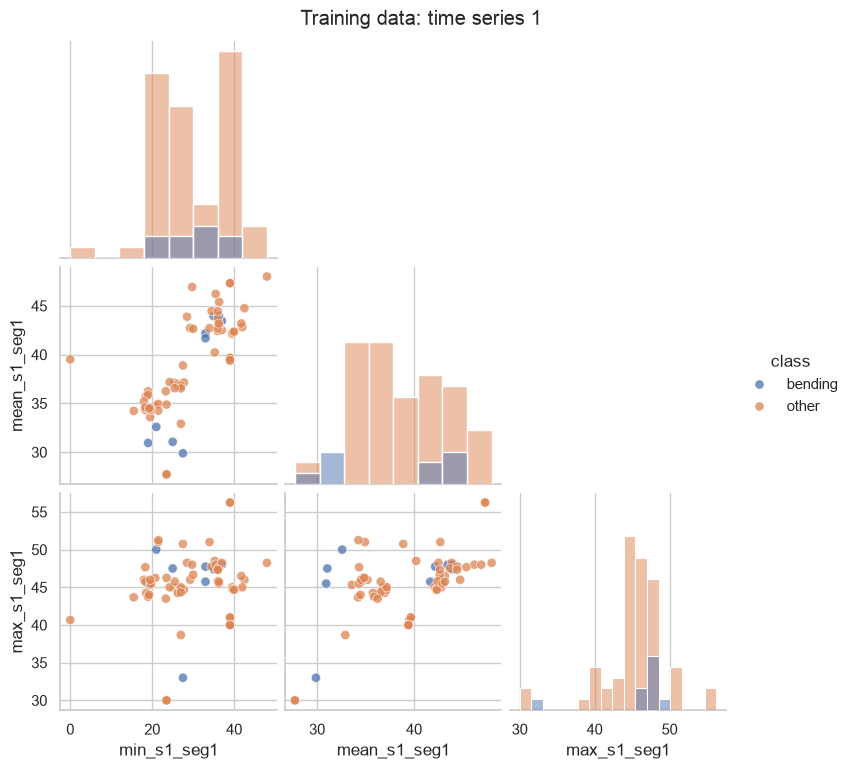

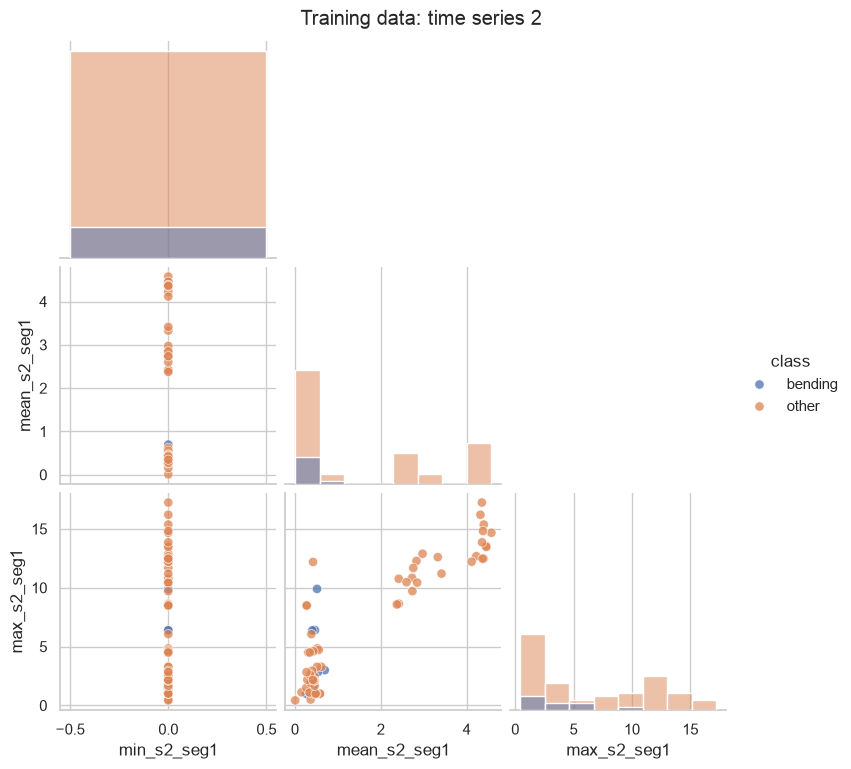

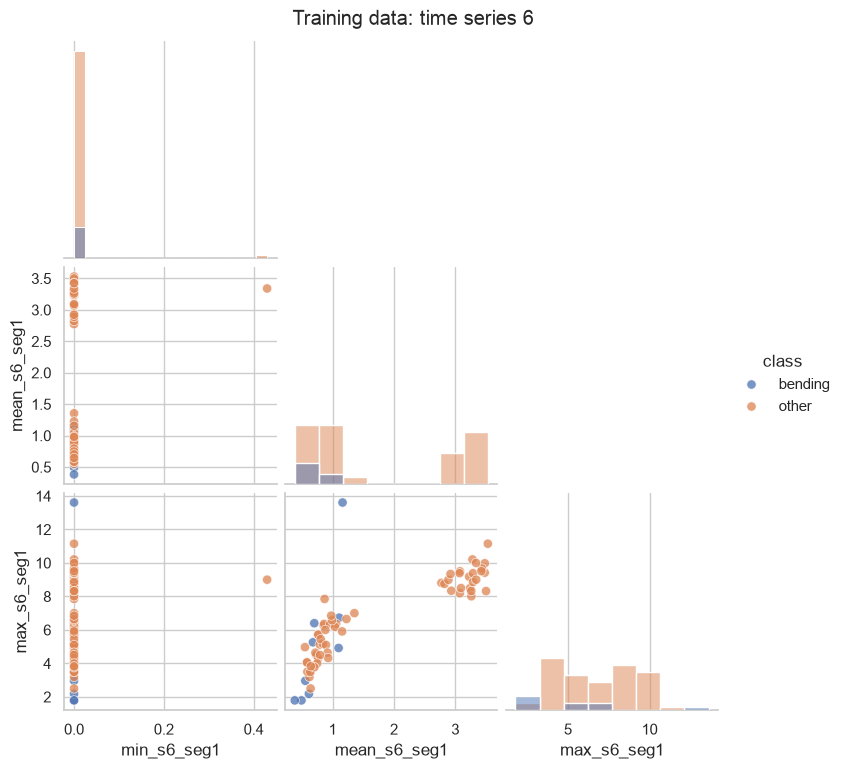

In [6]:
binary_label = np.where(metadata["activity"].str.startswith("bending"), "bending", "other")
plot_l1 = features_l1.loc[train_idx].copy()
plot_l1["class"] = binary_label[train_idx]

for series in [1, 2, 6]:
    columns = [f"{stat}_s{series}_seg1" for stat in ["min", "mean", "max"]]
    graph = sns.pairplot(
        plot_l1[columns + ["class"]], hue="class", corner=True,
        diag_kind="hist", plot_kws={"alpha": 0.75, "s": 45}
    )
    graph.fig.suptitle(f"Training data: time series {series}", y=1.02)
    plt.show()


The bending points are concentrated in smaller regions in several panels,
especially for time series 1 and 6. There is still overlap, so a model should
use several features together instead of relying on one cutoff.


#### ii. Splitted Plots


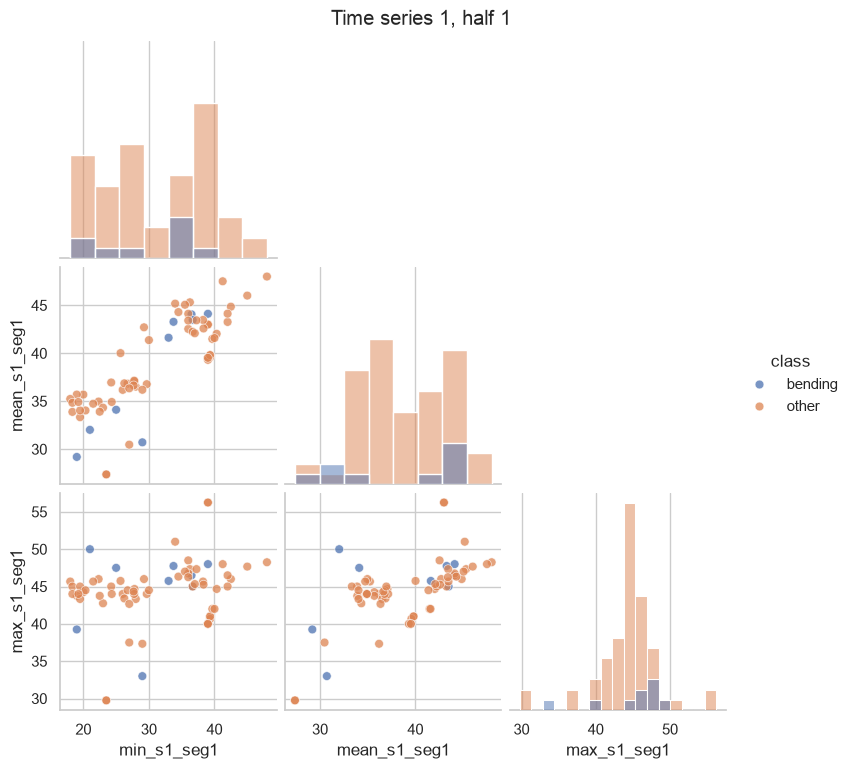

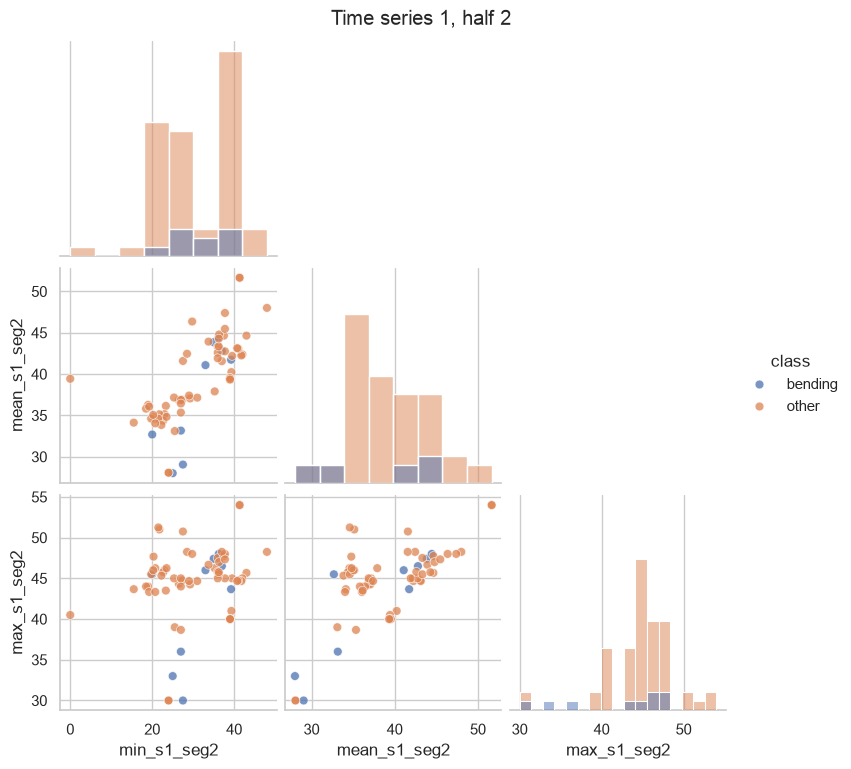

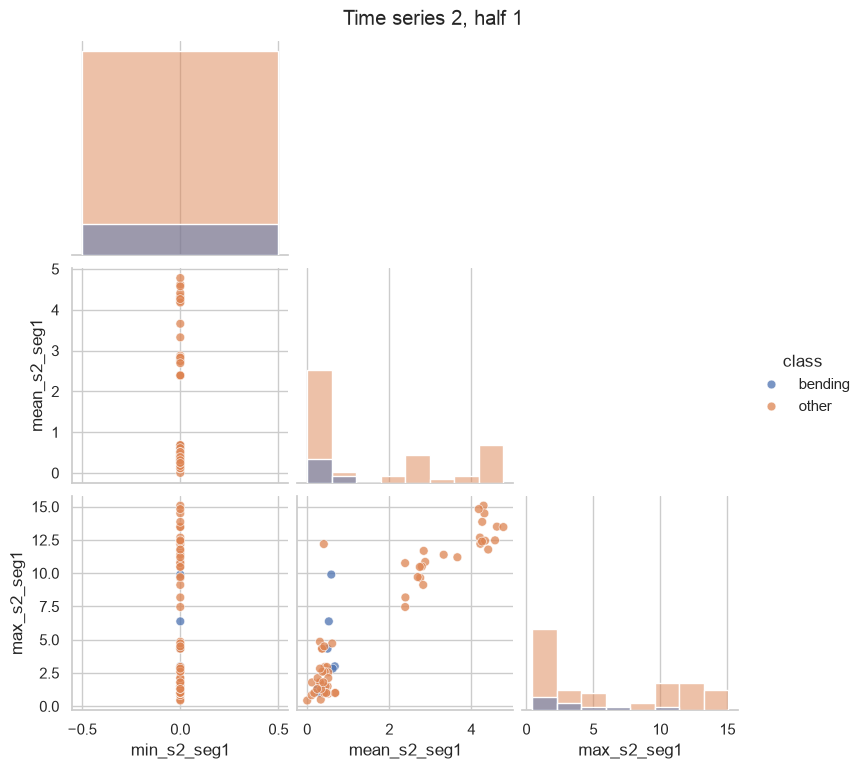

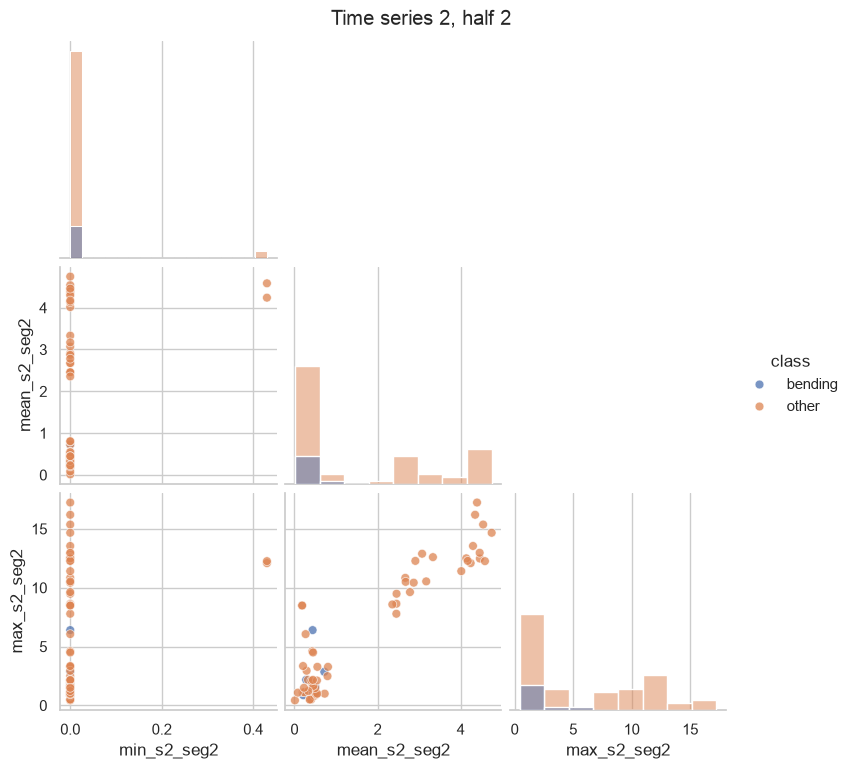

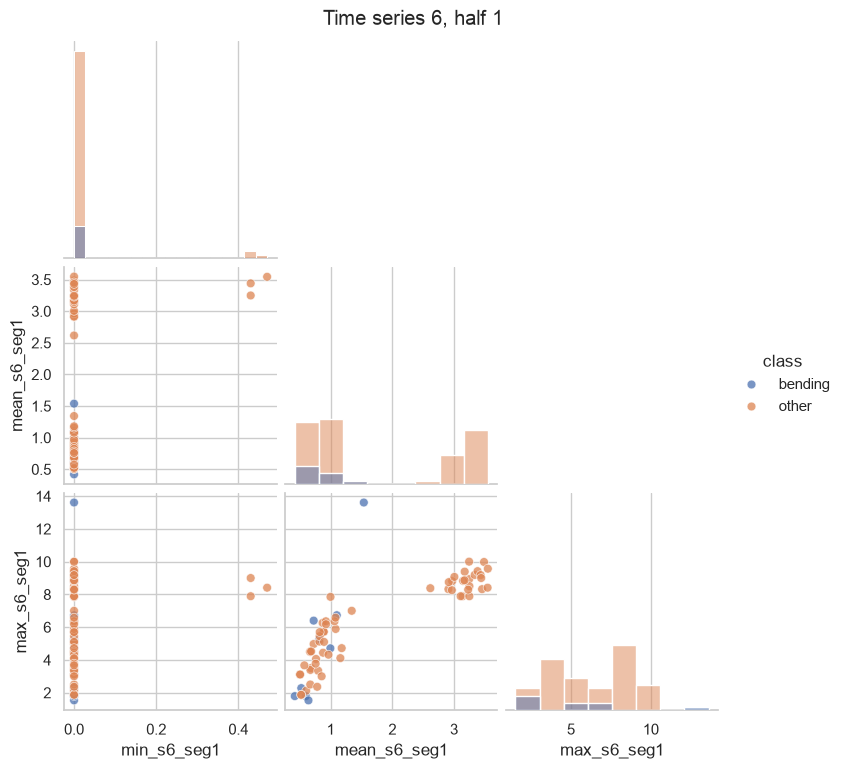

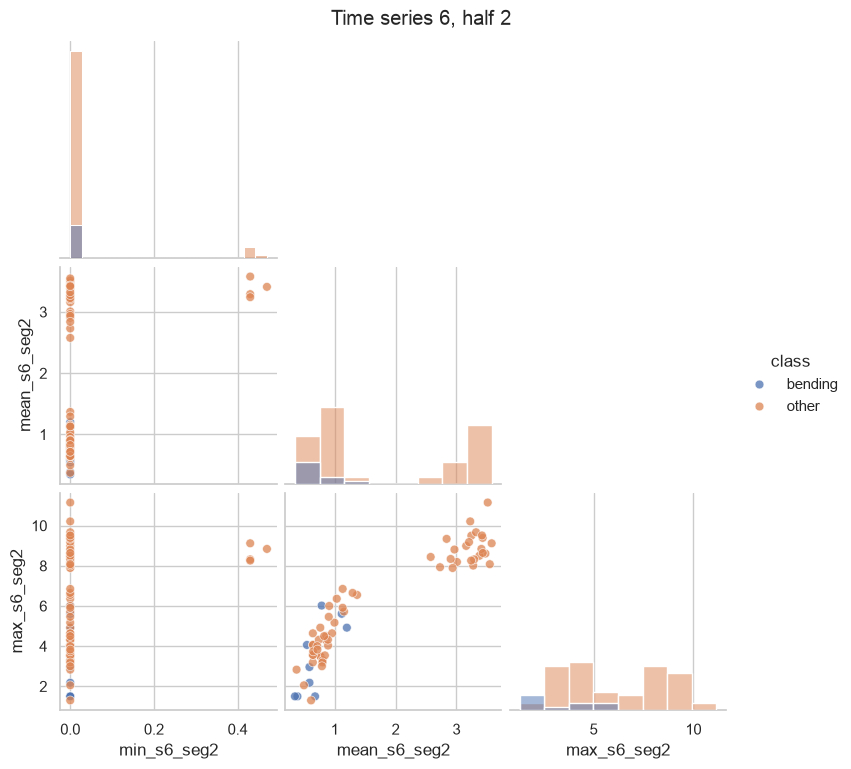

In [7]:
features_l2 = segmented_features(2)
plot_l2 = features_l2.loc[train_idx].copy()
plot_l2["class"] = binary_label[train_idx]

for series in [1, 2, 6]:
    for segment in [1, 2]:
        columns = [f"{stat}_s{series}_seg{segment}" for stat in ["min", "mean", "max"]]
        graph = sns.pairplot(
            plot_l2[columns + ["class"]], hue="class", corner=True,
            diag_kind="hist", plot_kws={"alpha": 0.75, "s": 40}
        )
        graph.fig.suptitle(
            f"Time series {series}, half {segment}", y=1.02
        )
        plt.show()


Splitting into two halves adds some separation in individual panels, but it does
not completely remove the overlap. The main difference is that the first and
second halves can now have different ranges and averages.


#### iii. Time Series Segments


I use recursive feature elimination (RFE), which the handout allows as the
alternative to manual p-value pruning. For every value of $l$, I test
$p \in \{5,10,15,20\}$ when that many features are available.

The scaler and RFE are inside the cross-validation pipeline. This is the right
order because feature selection is learned only from the training part of each
fold. Selecting features once on all 69 training instances and then running
cross-validation would be wrong: information from each validation fold would
already have influenced the selected columns.


In [8]:
y_binary_train = metadata.loc[train_idx, "activity"].str.startswith("bending").astype(int).to_numpy()
y_binary_test = metadata.loc[test_idx, "activity"].str.startswith("bending").astype(int).to_numpy()

binary_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
base_logit = LogisticRegression(C=1e6, solver="liblinear", max_iter=3000)
p_grid = [5, 10, 15, 20]
binary_rfe_rows = []

for l in range(1, 21):
    X_l = segmented_features(l).loc[train_idx]
    valid_p = [p for p in p_grid if p <= X_l.shape[1]]
    pipe = Pipeline(
        [
            ("scale", StandardScaler()),
            ("rfe", RFE(estimator=clone(base_logit), step=0.2)),
            ("logit", clone(base_logit)),
        ]
    )
    search = GridSearchCV(
        pipe,
        {"rfe__n_features_to_select": valid_p},
        cv=binary_cv,
        scoring="accuracy",
        n_jobs=1,
    )
    search.fit(X_l, y_binary_train)
    best_index = search.best_index_
    binary_rfe_rows.append(
        {
            "l": l,
            "p": search.best_params_["rfe__n_features_to_select"],
            "cv_accuracy": search.best_score_,
            "cv_std": search.cv_results_["std_test_score"][best_index],
        }
    )

binary_rfe_results = pd.DataFrame(binary_rfe_rows)
display(binary_rfe_results.round(4))
best_binary_row = binary_rfe_results.sort_values(
    ["cv_accuracy", "l", "p"], ascending=[False, True, True]
).iloc[0]
best_l = int(best_binary_row["l"])
best_p = int(best_binary_row["p"])
best_cv_accuracy = float(best_binary_row["cv_accuracy"])

display(Markdown(
    f"**Best RFE model:** $l={best_l}$, $p={best_p}$, "
    f"5-fold CV accuracy = **{best_cv_accuracy:.3f}**."
))


,l,p,cv_accuracy,cv_std
0,1,5,0.9429,0.0535
1,2,15,0.9132,0.0281
2,3,10,0.9429,0.0286
3,4,10,0.9429,0.0535
4,5,15,0.9429,0.0535
5,6,5,0.9857,0.0286
6,7,15,0.9560,0.0359
7,8,15,0.9571,0.0571
8,9,10,0.9000,0.0857
9,10,20,0.9429,0.0700


**Best RFE model:** $l=6$, $p=5$, 5-fold CV accuracy = **0.986**.

In [9]:
X_binary_train = segmented_features(best_l).loc[train_idx]
X_binary_test = segmented_features(best_l).loc[test_idx]

best_binary_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("rfe", RFE(estimator=clone(base_logit), n_features_to_select=best_p, step=0.2)),
        ("logit", clone(base_logit)),
    ]
)
best_binary_model.fit(X_binary_train, y_binary_train)

support = best_binary_model.named_steps["rfe"].support_
selected_names = X_binary_train.columns[support].tolist()
print("Selected features:")
display(pd.Series(selected_names, name="feature").to_frame())


Selected features:


,feature
0,std_s3_seg2
1,min_s5_seg2
2,max_s5_seg2
3,q1_s4_seg5
4,max_s1_seg6


#### iv. Confusion Matrix


,predicted other,predicted bending
actual other,60,0
actual bending,0,9


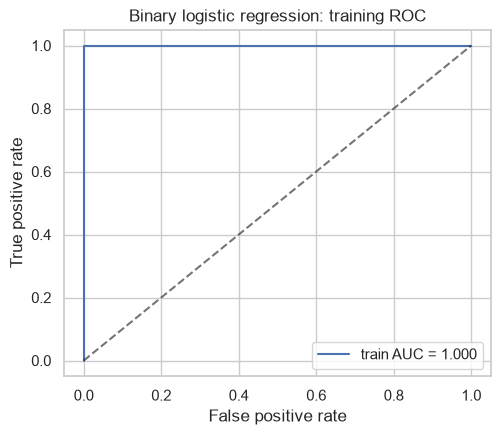

,term,coefficient,standard_error,z_value,p_value
0,intercept,-39.18587,146.96356,-0.26664,0.78975
1,std_s3_seg2,1.28748,42.83389,0.03006,0.97602
2,min_s5_seg2,9.69419,91.77527,0.10563,0.91588
3,max_s5_seg2,12.38565,75.88278,0.16322,0.87034
4,q1_s4_seg5,-29.74504,139.66765,-0.21297,0.83135
5,max_s1_seg6,-4.01773,32.58234,-0.12331,0.90186


In [10]:
def binary_wald_table(model, X, feature_names):
    scaled = model.named_steps["scale"].transform(X)
    selected = model.named_steps["rfe"].transform(scaled)
    fitted = model.named_steps["logit"]
    beta = np.r_[fitted.intercept_, fitted.coef_.ravel()]
    design = np.column_stack([np.ones(len(selected)), selected])
    probabilities = fitted.predict_proba(selected)[:, 1]
    weights = np.clip(probabilities * (1 - probabilities), 1e-10, None)
    information = design.T @ (weights[:, None] * design)
    covariance = np.linalg.pinv(information)
    standard_error = np.sqrt(np.clip(np.diag(covariance), 0, None))
    z_value = np.divide(
        beta, standard_error,
        out=np.full_like(beta, np.nan), where=standard_error > 0
    )
    p_value = 2 * norm.sf(np.abs(z_value))
    return pd.DataFrame(
        {
            "term": ["intercept"] + list(feature_names),
            "coefficient": beta,
            "standard_error": standard_error,
            "z_value": z_value,
            "p_value": p_value,
        }
    )


train_probability = best_binary_model.predict_proba(X_binary_train)[:, 1]
train_prediction = (train_probability >= 0.5).astype(int)
train_confusion = confusion_matrix(y_binary_train, train_prediction)
train_auc = roc_auc_score(y_binary_train, train_probability)

display(pd.DataFrame(
    train_confusion,
    index=["actual other", "actual bending"],
    columns=["predicted other", "predicted bending"],
))

fpr, tpr, _ = roc_curve(y_binary_train, train_probability)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr, tpr, label=f"train AUC = {train_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Binary logistic regression: training ROC")
plt.legend()
plt.show()

parameter_table = binary_wald_table(
    best_binary_model, X_binary_train, selected_names
)
display(parameter_table.round(5))


The Wald p-values should be interpreted carefully here. There are only nine
bending training instances, and near-separation makes the coefficient standard
errors unstable. I report them because they were requested, but I use the
cross-validated RFE result for feature selection.


#### v. Test Classifier


In [11]:
test_probability = best_binary_model.predict_proba(X_binary_test)[:, 1]
test_prediction = (test_probability >= 0.5).astype(int)
test_accuracy = accuracy_score(y_binary_test, test_prediction)
test_auc = roc_auc_score(y_binary_test, test_probability)
test_confusion = confusion_matrix(y_binary_test, test_prediction)

display(pd.DataFrame(
    test_confusion,
    index=["actual other", "actual bending"],
    columns=["predicted other", "predicted bending"],
))
display(Markdown(
    f"Cross-validation accuracy was **{best_cv_accuracy:.3f}**. "
    f"Test accuracy is **{test_accuracy:.3f}** and test AUC is "
    f"**{test_auc:.3f}**."
))


,predicted other,predicted bending
actual other,15,0
actual bending,1,3


Cross-validation accuracy was **0.986**. Test accuracy is **0.947** and test AUC is **0.967**.

#### vi. Separation


In [12]:
extreme_fraction = np.mean((train_probability < 0.01) | (train_probability > 0.99))
max_coefficient = np.abs(parameter_table["coefficient"]).max()
display(Markdown(
    f"The training classes are close to separated: {extreme_fraction:.1%} of "
    f"the fitted probabilities are below 0.01 or above 0.99, and the largest "
    f"absolute coefficient is {max_coefficient:.2f}. This explains the large "
    "coefficients and unstable Wald p-values."
))


The training classes are close to separated: 100.0% of the fitted probabilities are below 0.01 or above 0.99, and the largest absolute coefficient is 39.19. This explains the large coefficients and unstable Wald p-values.

#### vii. Imbalance


,training instances
other,60
bending,9


,predicted other,predicted bending
actual other,60,0
actual bending,0,9


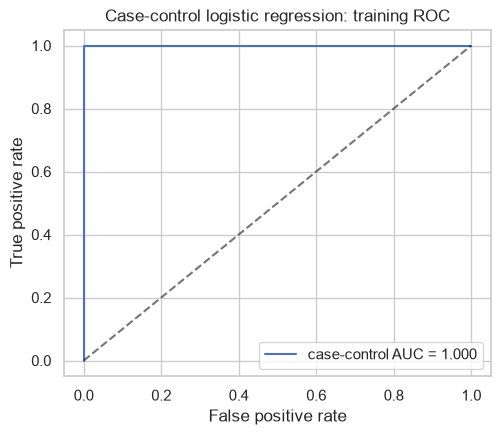

Population bending prior: 0.1304
Intercept adjustment: -1.8971
Training AUC after adjustment: 1.0000


In [13]:
class_counts = pd.Series(y_binary_train).value_counts().sort_index()
class_counts.index = ["other", "bending"]
display(class_counts.rename("training instances").to_frame())

scaled_train = best_binary_model.named_steps["scale"].transform(X_binary_train)
selected_train = best_binary_model.named_steps["rfe"].transform(scaled_train)
case_control_model = LogisticRegression(
    C=1e6, solver="liblinear", class_weight="balanced", max_iter=3000
)
case_control_model.fit(selected_train, y_binary_train)

population_prior = y_binary_train.mean()
intercept_adjustment = np.log(population_prior / (1 - population_prior))
adjusted_logit = (
    selected_train @ case_control_model.coef_.ravel()
    + case_control_model.intercept_[0]
    + intercept_adjustment
)
cc_probability = expit(adjusted_logit)
cc_prediction = (cc_probability >= 0.5).astype(int)
cc_confusion = confusion_matrix(y_binary_train, cc_prediction)
cc_auc = roc_auc_score(y_binary_train, cc_probability)

display(pd.DataFrame(
    cc_confusion,
    index=["actual other", "actual bending"],
    columns=["predicted other", "predicted bending"],
))

fpr_cc, tpr_cc, _ = roc_curve(y_binary_train, cc_probability)
plt.figure(figsize=(5.5, 4.5))
plt.plot(fpr_cc, tpr_cc, label=f"case-control AUC = {cc_auc:.3f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.6)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Case-control logistic regression: training ROC")
plt.legend()
plt.show()

print(f"Population bending prior: {population_prior:.4f}")
print(f"Intercept adjustment: {intercept_adjustment:.4f}")
print(f"Training AUC after adjustment: {cc_auc:.4f}")


The training data are imbalanced (nine bending versus sixty other instances).
I used balanced case-control weights and then shifted the intercept back to the
original bending prior. The intercept correction changes calibrated
probabilities but not their ranking, so it does not change the ROC AUC.


### (b) Binary Classification Using L1-penalized Logistic Regression


#### i. Time Series Segments


In [14]:
l1_cv_rows = []
c_grid = np.logspace(-3, 3, 7)

for l in range(1, 21):
    X_l = segmented_features(l).loc[train_idx]
    pipe = Pipeline(
        [
            ("scale", StandardScaler()),
            ("logit", LogisticRegression(
                penalty="l1", l1_ratio=1.0,
                solver="liblinear", max_iter=5000
            )),
        ]
    )
    search = GridSearchCV(
        pipe, {"logit__C": c_grid}, cv=binary_cv,
        scoring="accuracy", n_jobs=1
    )
    search.fit(X_l, y_binary_train)
    l1_cv_rows.append(
        {"l": l, "C": search.best_params_["logit__C"], "cv_accuracy": search.best_score_}
    )

l1_cv_results = pd.DataFrame(l1_cv_rows)
display(l1_cv_results.round(4))
best_l1_row = l1_cv_results.sort_values(
    ["cv_accuracy", "l", "C"], ascending=[False, True, True]
).iloc[0]
l1_best_l = int(best_l1_row["l"])
l1_best_c = float(best_l1_row["C"])
l1_best_cv = float(best_l1_row["cv_accuracy"])

binary_l1_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(
            penalty="l1", l1_ratio=1.0, C=l1_best_c,
            solver="liblinear", max_iter=5000
        )),
    ]
)
binary_l1_model.fit(segmented_features(l1_best_l).loc[train_idx], y_binary_train)
l1_test_prediction = binary_l1_model.predict(segmented_features(l1_best_l).loc[test_idx])
l1_test_probability = binary_l1_model.predict_proba(segmented_features(l1_best_l).loc[test_idx])[:, 1]
l1_test_accuracy = accuracy_score(y_binary_test, l1_test_prediction)
l1_test_auc = roc_auc_score(y_binary_test, l1_test_probability)
nonzero_coefficients = int(np.count_nonzero(binary_l1_model.named_steps["logit"].coef_))

display(Markdown(
    f"**Best L1 model:** $l={l1_best_l}$, $C={l1_best_c:g}$, "
    f"CV accuracy = **{l1_best_cv:.3f}**. It keeps "
    f"**{nonzero_coefficients}** nonzero coefficients. Test accuracy is "
    f"**{l1_test_accuracy:.3f}** and test AUC is **{l1_test_auc:.3f}**."
))


,l,C,cv_accuracy
0,1,1.0,0.9714
1,2,1.0,0.9429
2,3,1.0,0.9571
3,4,1.0,0.9571
4,5,100.0,0.9275
5,6,1000.0,0.9429
6,7,100.0,0.9429
7,8,100.0,0.9286
8,9,1.0,0.9286
9,10,10.0,0.9429


**Best L1 model:** $l=11$, $C=1$, CV accuracy = **0.986**. It keeps **8** nonzero coefficients. Test accuracy is **0.947** and test AUC is **1.000**.

#### ii. Comparison


In [15]:
binary_comparison = pd.DataFrame(
    [
        {
            "method": "RFE + logistic regression",
            "l": best_l,
            "selected_features": best_p,
            "cv_accuracy": best_cv_accuracy,
            "test_accuracy": test_accuracy,
            "test_auc": test_auc,
        },
        {
            "method": "L1 logistic regression",
            "l": l1_best_l,
            "selected_features": nonzero_coefficients,
            "cv_accuracy": l1_best_cv,
            "test_accuracy": l1_test_accuracy,
            "test_auc": l1_test_auc,
        },
    ]
)
display(binary_comparison.round(4))

better_binary = binary_comparison.sort_values(
    ["test_accuracy", "test_auc"], ascending=False
).iloc[0]["method"]
display(Markdown(
    f"On this split, **{better_binary}** has the better test result. "
    "The L1 version is easier to implement because regularization and feature "
    "selection happen in the same estimator; the p-value/RFE route needs a "
    "separate selection step and is more sensitive to separation."
))


,method,l,selected_features,cv_accuracy,test_accuracy,test_auc
0,RFE + logistic regression,6,5,0.9857,0.9474,0.9667
1,L1 logistic regression,11,8,0.9857,0.9474,1.0000


On this split, **L1 logistic regression** has the better test result. The L1 version is easier to implement because regularization and feature selection happen in the same estimator; the p-value/RFE route needs a separate selection step and is more sensitive to separation.

### (c) Multi-class Classification (The Realistic Case)


#### i. Time Series Segments


The smallest training class is `bending2`, with four instances. I therefore use
four stratified folds for multiclass tuning. Five folds would force at least one
validation fold to miss that class.


,l,C,cv_accuracy
0,1,1,0.8995
1,2,1,0.8848
2,3,1,0.8399
3,4,1,0.8407
4,5,1,0.8399
5,6,1,0.7974
6,7,1,0.8391
7,8,1,0.7958
8,9,1,0.7982
9,10,1,0.7680


**Best multiclass L1 model:** $l=1$, $C=1$, CV accuracy = **0.900**, test error = **0.105**.

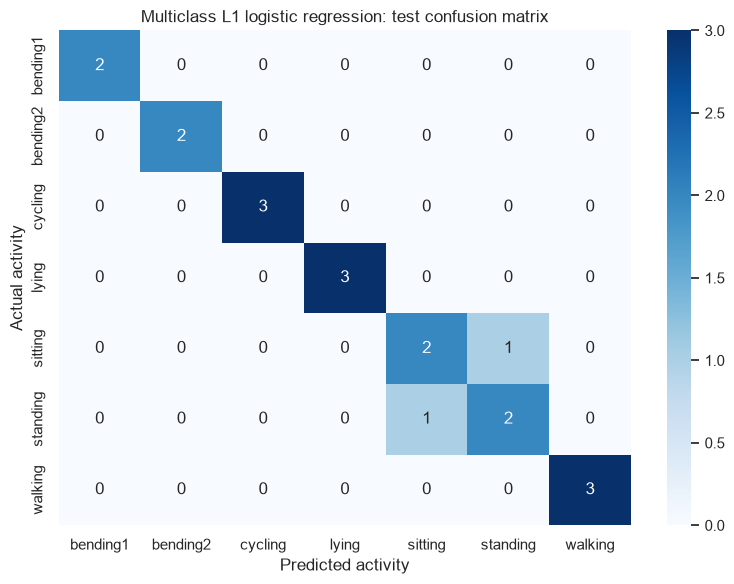

In [16]:
y_multi_train = metadata.loc[train_idx, "activity"].to_numpy()
y_multi_test = metadata.loc[test_idx, "activity"].to_numpy()
multi_cv = StratifiedKFold(n_splits=4, shuffle=True, random_state=RANDOM_SEED)
multi_c_grid = [0.01, 0.1, 1]
multi_l1_rows = []

for l in range(1, 21):
    X_l = segmented_features(l).loc[train_idx]
    pipe = Pipeline(
        [
            ("scale", StandardScaler()),
            ("logit", LogisticRegression(
                penalty="l1", l1_ratio=1.0,
                solver="saga", max_iter=2000,
                tol=1e-2, random_state=RANDOM_SEED
            )),
        ]
    )
    search = GridSearchCV(
        pipe, {"logit__C": multi_c_grid}, cv=multi_cv,
        scoring="accuracy", n_jobs=1
    )
    search.fit(X_l, y_multi_train)
    multi_l1_rows.append(
        {"l": l, "C": search.best_params_["logit__C"], "cv_accuracy": search.best_score_}
    )

multi_l1_results = pd.DataFrame(multi_l1_rows)
display(multi_l1_results.round(4))
best_multi_row = multi_l1_results.sort_values(
    ["cv_accuracy", "l", "C"], ascending=[False, True, True]
).iloc[0]
multi_best_l = int(best_multi_row["l"])
multi_best_c = float(best_multi_row["C"])
multi_best_cv = float(best_multi_row["cv_accuracy"])

multi_l1_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("logit", LogisticRegression(
            penalty="l1", l1_ratio=1.0, C=multi_best_c, solver="saga",
            max_iter=2000, tol=1e-2, random_state=RANDOM_SEED
        )),
    ]
)
multi_l1_model.fit(segmented_features(multi_best_l).loc[train_idx], y_multi_train)
multi_prediction = multi_l1_model.predict(segmented_features(multi_best_l).loc[test_idx])
multi_probability = multi_l1_model.predict_proba(segmented_features(multi_best_l).loc[test_idx])
multi_test_error = 1 - accuracy_score(y_multi_test, multi_prediction)
multi_classes = multi_l1_model.named_steps["logit"].classes_

display(Markdown(
    f"**Best multiclass L1 model:** $l={multi_best_l}$, "
    f"$C={multi_best_c:g}$, CV accuracy = **{multi_best_cv:.3f}**, "
    f"test error = **{multi_test_error:.3f}**."
))

multi_cm = confusion_matrix(y_multi_test, multi_prediction, labels=multi_classes)
plt.figure(figsize=(8, 6))
sns.heatmap(
    multi_cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=multi_classes, yticklabels=multi_classes
)
plt.xlabel("Predicted activity")
plt.ylabel("Actual activity")
plt.title("Multiclass L1 logistic regression: test confusion matrix")
plt.tight_layout()
plt.show()


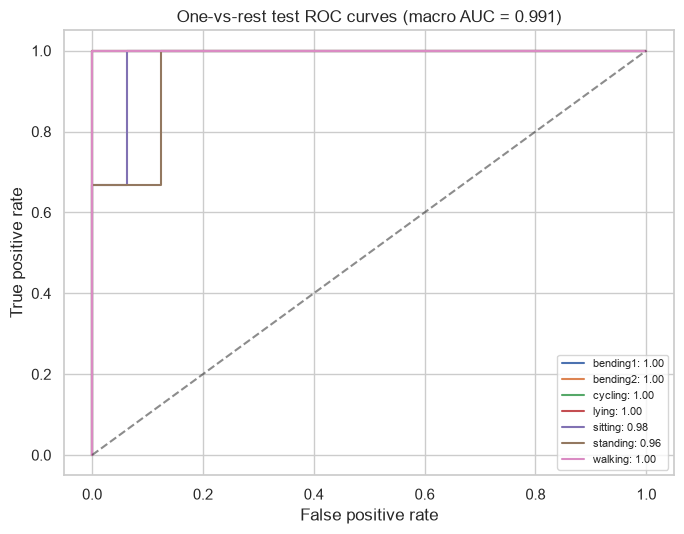

In [17]:
y_multi_test_bin = label_binarize(y_multi_test, classes=multi_classes)
macro_auc = roc_auc_score(
    y_multi_test_bin, multi_probability, average="macro", multi_class="ovr"
)

plt.figure(figsize=(7, 5.5))
for class_index, activity in enumerate(multi_classes):
    fpr_class, tpr_class, _ = roc_curve(
        y_multi_test_bin[:, class_index], multi_probability[:, class_index]
    )
    class_auc = auc(fpr_class, tpr_class)
    plt.plot(fpr_class, tpr_class, label=f"{activity}: {class_auc:.2f}")
plt.plot([0, 1], [0, 1], "k--", alpha=0.5)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title(f"One-vs-rest test ROC curves (macro AUC = {macro_auc:.3f})")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


For a multiclass confusion matrix, rows are actual classes and columns are
predicted classes. The diagonal contains correct predictions. The ROC curves
use one-vs-rest: one activity is positive and the other six are negative. I
report the macro AUC so every activity receives equal weight.


#### ii. Naive Bayes


Gaussian NB Multinomial NB            
   cv_accuracy          alpha cv_accuracy
l                                        
1       0.8701            0.1      0.7982
2       0.8562            0.1      0.7974
3       0.7533            0.1      0.7827
4       0.7108            0.1      0.7835
5       0.7541            0.1      0.7974
6       0.6806            0.1      0.7974
7       0.6658            0.1      0.7688
8       0.6356            0.1      0.7688
9       0.6234            0.1      0.7974
10      0.6806            0.1      0.8260
11      0.6528            0.1      0.7835
12      0.6234            0.1      0.7982
13      0.6242            0.1      0.7966
14      0.5948            0.1      0.7688
15      0.5956            0.1      0.7827
16      0.6087            0.1      0.7827
17      0.5809            0.1      0.7827
18      0.5523            0.1      0.8121
19      0.5809            0.1      0.7247
20      0.5801            0.1      0.7827

,method,l,cv_accuracy,test_error
0,Gaussian NB,1,0.8701,0.1053
1,Multinomial NB,10,0.8260,0.1579


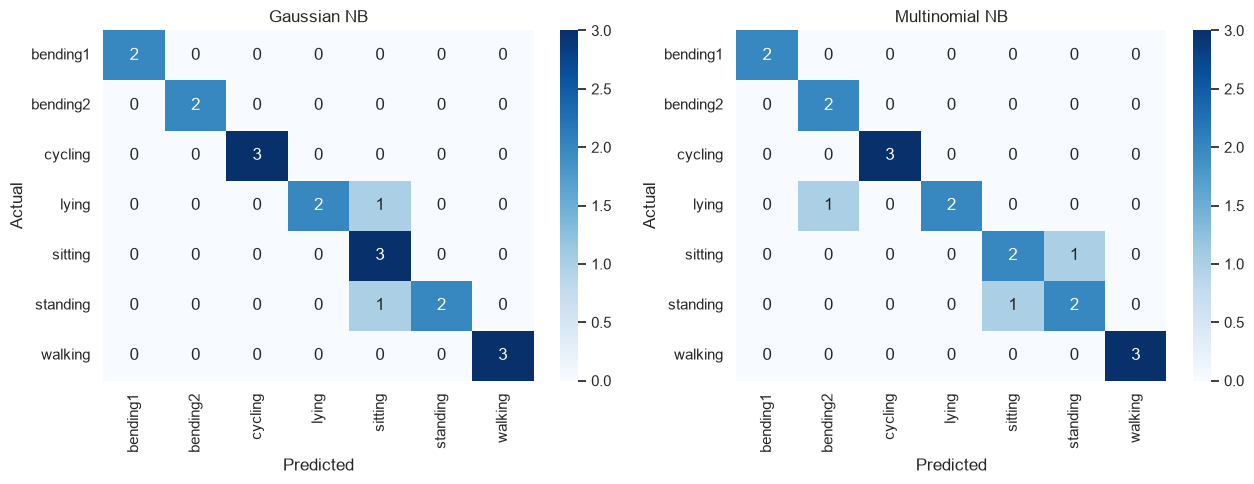

In [18]:
gaussian_rows = []
multinomial_rows = []
alpha_grid = [0.1, 1.0, 10.0]

for l in range(1, 21):
    X_l = segmented_features(l).loc[train_idx]

    gaussian_pipe = Pipeline(
        [("scale", StandardScaler()), ("nb", GaussianNB())]
    )
    gaussian_scores = cross_val_score(
        gaussian_pipe, X_l, y_multi_train,
        cv=multi_cv, scoring="accuracy", n_jobs=1
    )
    gaussian_rows.append({"l": l, "cv_accuracy": gaussian_scores.mean()})

    multinomial_pipe = Pipeline(
        [("scale", MinMaxScaler()), ("nb", MultinomialNB())]
    )
    multinomial_search = GridSearchCV(
        multinomial_pipe, {"nb__alpha": alpha_grid},
        cv=multi_cv, scoring="accuracy", n_jobs=1
    )
    multinomial_search.fit(X_l, y_multi_train)
    multinomial_rows.append(
        {
            "l": l,
            "alpha": multinomial_search.best_params_["nb__alpha"],
            "cv_accuracy": multinomial_search.best_score_,
        }
    )

gaussian_results = pd.DataFrame(gaussian_rows)
multinomial_results = pd.DataFrame(multinomial_rows)
display(pd.concat(
    {
        "Gaussian NB": gaussian_results.set_index("l"),
        "Multinomial NB": multinomial_results.set_index("l"),
    },
    axis=1,
).round(4))

gaussian_best = gaussian_results.sort_values(
    ["cv_accuracy", "l"], ascending=[False, True]
).iloc[0]
multinomial_best = multinomial_results.sort_values(
    ["cv_accuracy", "l", "alpha"], ascending=[False, True, True]
).iloc[0]

gaussian_l = int(gaussian_best["l"])
multinomial_l = int(multinomial_best["l"])
gaussian_model = Pipeline(
    [("scale", StandardScaler()), ("nb", GaussianNB())]
)
multinomial_model = Pipeline(
    [
        ("scale", MinMaxScaler()),
        ("nb", MultinomialNB(alpha=float(multinomial_best["alpha"]))),
    ]
)
gaussian_model.fit(segmented_features(gaussian_l).loc[train_idx], y_multi_train)
multinomial_model.fit(segmented_features(multinomial_l).loc[train_idx], y_multi_train)

gaussian_prediction = gaussian_model.predict(segmented_features(gaussian_l).loc[test_idx])
multinomial_prediction = multinomial_model.predict(segmented_features(multinomial_l).loc[test_idx])
gaussian_test_error = 1 - accuracy_score(y_multi_test, gaussian_prediction)
multinomial_test_error = 1 - accuracy_score(y_multi_test, multinomial_prediction)

nb_summary = pd.DataFrame(
    [
        {
            "method": "Gaussian NB",
            "l": gaussian_l,
            "cv_accuracy": gaussian_best["cv_accuracy"],
            "test_error": gaussian_test_error,
        },
        {
            "method": "Multinomial NB",
            "l": multinomial_l,
            "cv_accuracy": multinomial_best["cv_accuracy"],
            "test_error": multinomial_test_error,
        },
    ]
)
display(nb_summary.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, prediction, title in [
    (axes[0], gaussian_prediction, "Gaussian NB"),
    (axes[1], multinomial_prediction, "Multinomial NB"),
]:
    matrix = confusion_matrix(y_multi_test, prediction, labels=ACTIVITY_ORDER)
    sns.heatmap(
        matrix, annot=True, fmt="d", cmap="Blues", ax=ax,
        xticklabels=ACTIVITY_ORDER, yticklabels=ACTIVITY_ORDER
    )
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()


#### iii. Comparison


In [19]:
multiclass_comparison = pd.DataFrame(
    [
        {
            "method": "L1 multinomial logistic regression",
            "cv_accuracy": multi_best_cv,
            "test_error": multi_test_error,
        },
        {
            "method": "Gaussian NB",
            "cv_accuracy": gaussian_best["cv_accuracy"],
            "test_error": gaussian_test_error,
        },
        {
            "method": "Multinomial NB",
            "cv_accuracy": multinomial_best["cv_accuracy"],
            "test_error": multinomial_test_error,
        },
    ]
)
display(multiclass_comparison.round(4))
best_multiclass_method = multiclass_comparison.sort_values(
    ["test_error", "cv_accuracy"], ascending=[True, False]
).iloc[0]["method"]
display(Markdown(
    f"For this data split, **{best_multiclass_method}** is my choice after "
    "comparing test error and cross-validation accuracy. The L1 model and "
    "Gaussian NB tie on test error, but the L1 model has the higher CV "
    "accuracy. Multinomial NB is less natural here because these measurements "
    "are continuous values rather than counts."
))


,method,cv_accuracy,test_error
0,L1 multinomial logistic regression,0.8995,0.1053
1,Gaussian NB,0.8701,0.1053
2,Multinomial NB,0.8260,0.1579


For this data split, **L1 multinomial logistic regression** is my choice after comparing test error and cross-validation accuracy. The L1 model and Gaussian NB tie on test error, but the L1 model has the higher CV accuracy. Multinomial NB is less natural here because these measurements are continuous values rather than counts.

## 3. ISLR 4.8.3

For class $k$, Bayes' rule assigns $x$ to the class with the largest posterior
probability. Terms that do not depend on $k$ can be removed, so the class score
is

$$
\delta_k(x)=\log(\pi_k)-\log(\sigma_k)
-\frac{(x-\mu_k)^2}{2\sigma_k^2}.
$$

Expanding the squared term gives

$$
\delta_k(x)=
-\frac{x^2}{2\sigma_k^2}
+\frac{\mu_k}{\sigma_k^2}x
-\frac{\mu_k^2}{2\sigma_k^2}
-\log(\sigma_k)+\log(\pi_k).
$$

The score contains an $x^2$ term. Since each class can have a different
variance, the coefficient of $x^2$ depends on $k$. Setting
$\delta_k(x)=\delta_j(x)$ therefore gives a quadratic equation in $x$. This is
why QDA has a quadratic, rather than linear, decision boundary. If all class
variances were equal, the $x^2$ terms would cancel and the boundary would be
linear, which is the LDA case.


## 4. ISLR 4.8.7

Let $D$ mean that the company issues a dividend. The prior probabilities are
$P(D)=0.8$ and $P(D^c)=0.2$. Both classes have variance $36$, so the common
normal-density constant cancels in Bayes' rule. For $X=4$,

$$
\begin{aligned}
P(D\mid X=4)
&=\frac{0.8\exp\left[-(4-10)^2/(2\cdot36)\right]}
{0.8\exp\left[-(4-10)^2/(2\cdot36)\right]
+0.2\exp\left[-(4-0)^2/(2\cdot36)\right]}\\
&=\frac{0.8e^{-0.5}}{0.8e^{-0.5}+0.2e^{-2/9}}\\
&\approx 0.752.
\end{aligned}
$$

Therefore, the predicted probability that the company issues a dividend is
about **75.2%**.
